# Домашняя работа 4.1. Вернуть маятник в заданное положение
## Жёлтый уровень

$$
\ddot\theta+\sin\theta=0,\qquad \theta(0)=\theta(4)=0.
$$

Подбирается начальная скорость $s=\dot\theta(0)$ в диапазоне $[-1.99,1.99]$.
Время безразмерное, углы в радианах. Невязка $R(s)=\theta(4;s)$ считается
по самому углу, без приведения по модулю $2\pi$.
Для запуска нужны NumPy, Matplotlib и Pillow.
[Условие задания](https://github.com/yartmihant/Students6Year2026#readme).

## 1. Стрельба и производная невязки

Задача Коши решается методом RK4. Для Ньютона одновременно интегрируется
чувствительность к начальной скорости:

$$
p=\frac{\partial\theta}{\partial s},\quad q=\frac{\partial\dot\theta}{\partial s},
\qquad \dot p=q,\quad \dot q=-\cos\theta\,p,
\qquad p(0)=0,\ q(0)=1.
$$

Тогда $R'(s)=p(4)$. Для поиска всех корней сначала строится график невязки,
а интервалы со сменой знака уточняются бисекцией. Нулевое решение учитывается отдельно.

Корни и конечные углы:
s = -1.604813034731,  θ(4) =  2.189e-13
s =  0.000000000000,  θ(4) =  0.000e+00
s =  1.604813034731,  θ(4) = -2.189e-13


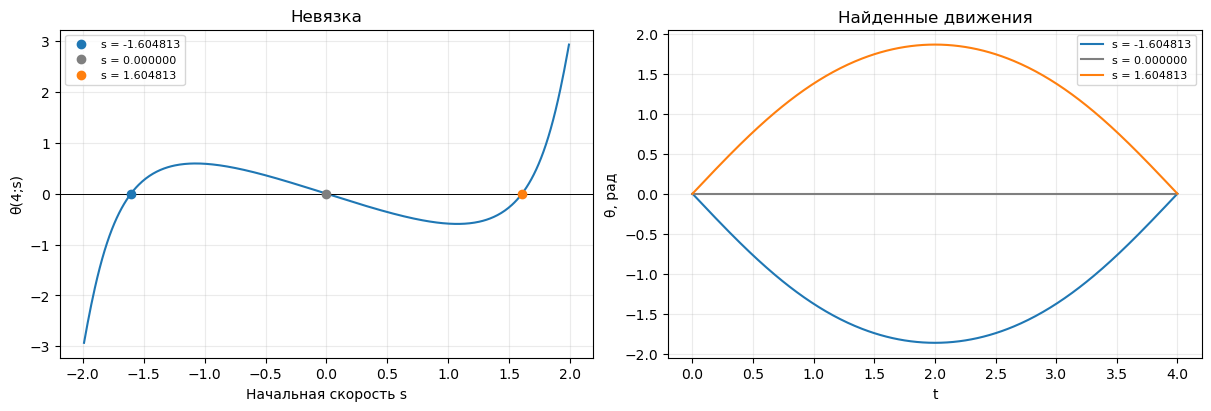

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from io import BytesIO
from base64 import b64encode
from PIL import Image as PILImage
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.grid": True, "grid.alpha": 0.25})
T = 4.0
h_main = 0.01
bound = 1.99


def initial(s):
    s = np.atleast_1d(s)
    state = np.zeros((len(s), 4))
    state[:, 1] = s
    state[:, 3] = 1
    return state


def rhs(state):
    theta, omega, p, q = state.T
    return np.column_stack((omega, -np.sin(theta), q, -np.cos(theta)*p))


def rk4(state, h):
    k1 = rhs(state)
    k2 = rhs(state + h*k1/2)
    k3 = rhs(state + h*k2/2)
    k4 = rhs(state + h*k3)
    return state + h*(k1+2*k2+2*k3+k4)/6


def endpoint(s, h):
    state = initial(s)
    for _ in range(round(T/h)):
        state = rk4(state, h)
    return state[:, 0], state[:, 2]


def trajectory(s, h):
    state = initial(s)
    n = round(T/h)
    values = np.empty((n+1, len(state), 2))
    values[0] = state[:, :2]
    for i in range(n):
        state = rk4(state, h)
        values[i+1] = state[:, :2]
    return np.arange(n+1)*h, values


def bisect(a, b, h, tol=1e-12):
    fa, fb = endpoint([a, b], h)[0]
    if fa*fb >= 0:
        raise ValueError("Нужны разные знаки невязки.")
    for _ in range(70):
        m = (a+b)/2
        fm = endpoint(m, h)[0][0]
        if abs(fm) < tol:
            return m
        if fa*fm < 0:
            b = m
        else:
            a, fa = m, fm
    raise RuntimeError("Бисекция не сошлась.")


speeds = np.linspace(-bound, bound, 401)
residuals, derivatives = endpoint(speeds, h_main)
brackets = [(speeds[i], speeds[i+1]) for i in range(len(speeds)-1)
            if residuals[i]*residuals[i+1] < 0
            and min(abs(residuals[i]), abs(residuals[i+1])) > 1e-10]
roots = np.sort([0.0] + [bisect(a,b,h_main) for a,b in brackets])
print("Корни и конечные углы:")
for s, value in zip(roots, endpoint(roots, h_main)[0]):
    print(f"s = {s: .12f},  θ(4) = {value: .3e}")

t, movements = trajectory(roots, h_main)
colors = ["tab:blue", "tab:gray", "tab:orange"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(speeds, residuals)
axes[0].axhline(0, color="black", linewidth=0.7)
for j, s in enumerate(roots):
    axes[0].plot(s, 0, "o", color=colors[j], label=f"s = {s:.6f}")
    axes[1].plot(t, movements[:, j, 0], color=colors[j], label=f"s = {s:.6f}")
axes[0].set(xlabel="Начальная скорость s", ylabel="θ(4;s)", title="Невязка")
axes[1].set(xlabel="t", ylabel="θ, рад", title="Найденные движения")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

## 2. Зависимость Ньютона от начального приближения

Применяется обычный шаг $s_{n+1}=s_n-R(s_n)/R'(s_n)$ без уменьшения длины шага.
Чтобы исследовать заданный диапазон, при выходе очередного приближения из
$[-1.99,1.99]$ расчёт останавливается с отдельным статусом. Значение не обрезается
до границы. Это правило остановки данной реализации, а не утверждение,
что неограниченный Ньютон обязательно расходится.

Допуск невязки равен $10^{-10}$, порог малой производной — $10^{-8}$,
предел числа обновлений — 30. Проверяется 801 начальное приближение.
Карта конечна по разрешению: более узкие области между отсчётами могут не обнаружиться.

Отрицательный корень: 146 начальных приближений
Нулевой корень: 359 начальных приближений
Положительный корень: 146 начальных приближений
Выход из диапазона: 150 начальных приближений


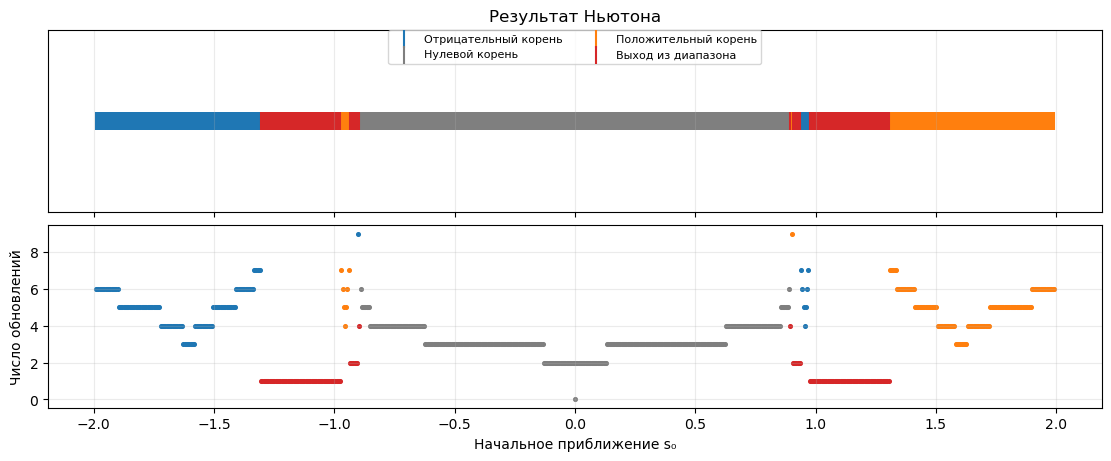

In [2]:
def newton_map(starts, h):
    s = starts.copy()
    status = np.full(len(s), -4, dtype=int)
    iterations = np.zeros(len(s), dtype=int)
    active = np.ones(len(s), dtype=bool)
    for n in range(31):
        ids = np.flatnonzero(active)
        if len(ids) == 0:
            break
        residual, derivative = endpoint(s[ids], h)
        converged = np.abs(residual) <= 1e-10
        for index in np.flatnonzero(converged):
            i = ids[index]
            nearest = np.argmin(np.abs(roots-s[i]))
            status[i] = nearest if abs(roots[nearest]-s[i]) < 1e-5 else -5
            active[i] = False
        pending = ~converged
        if n == 30:
            break
        small = pending & (np.abs(derivative) < 1e-8)
        status[ids[small]] = -2
        active[ids[small]] = False
        good = pending & ~small
        next_s = s[ids[good]] - residual[good]/derivative[good]
        outside = (np.abs(next_s) > bound) | ~np.isfinite(next_s)
        good_ids = ids[good]
        status[good_ids[outside]] = -1
        active[good_ids[outside]] = False
        s[good_ids] = next_s
        iterations[good_ids] += 1
    return s, status, iterations


starts = np.linspace(-bound, bound, 801)
final_s, status, iterations = newton_map(starts, h_main)
labels = {0: "Отрицательный корень", 1: "Нулевой корень", 2: "Положительный корень",
          -1: "Выход из диапазона", -2: "Малая производная", -4: "Лимит итераций", -5: "Другой корень"}
palette = {0:colors[0], 1:colors[1], 2:colors[2], -1:"tab:red", -2:"purple", -4:"black", -5:"green"}
fig, axes = plt.subplots(2, 1, figsize=(11, 4.5), sharex=True, layout="constrained")
for key in labels:
    mask = status == key
    if not np.any(mask):
        continue
    axes[0].scatter(starts[mask], np.zeros(mask.sum()), c=palette[key], marker="|", s=150, label=labels[key])
    axes[1].scatter(starts[mask], iterations[mask], c=palette[key], s=7)
    print(f"{labels[key]}: {mask.sum()} начальных приближений")
axes[0].set(yticks=[], title="Результат Ньютона")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.03), ncol=2, fontsize=8)
axes[1].set(xlabel="Начальное приближение s₀", ylabel="Число обновлений")
plt.show()

## 3. Уменьшение шага и проверка числа решений

На каждом шаге начальные скорости заново находятся бисекцией.
Сравниваются скорости, невязки и траектории в общих узлах с шагом 0.04.
Опорный расчёт с $h=0.005$ также численный.

Для независимой проверки используется энергия $E=s^2/2$.
При $|s|<2$ движение колебательное. Время первого возвращения в ноль равно

$$
\tau(s)=2\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1-(s/2)^2\sin^2\varphi}}.
$$

Оно растёт от $\pi$ до бесконечности с увеличением $|s|$.
Второе возвращение требует времени не меньше $2\pi>4$.
Поэтому в данном диапазоне возможны только покой и два симметричных ненулевых
движения, для которых $\tau(s)=4$.
Интеграл ниже вычисляется квадратурой Гаусса по 80 узлам.

h       s положительный   |θ(4)|         max Δθ к h=0.005    max |E(t)-E(0)|
0.04    1.60481302386    3.478e-13    3.230e-08             2.739e-08
0.02    1.60481303406    4.602e-13    2.005e-09             1.646e-09
0.01    1.60481303473    2.189e-13    1.179e-10             1.007e-10
0.005   1.60481303477    1.065e-14    0.000e+00             6.231e-12
Время возвращения по квадратуре: 3.999999999994


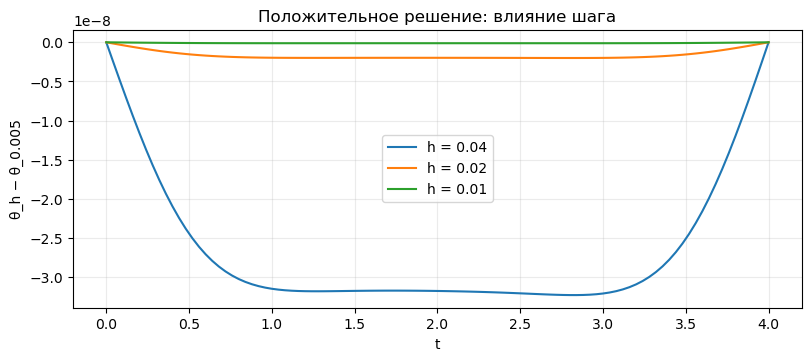

In [3]:
steps = [0.04, 0.02, 0.01, 0.005]
refined = {}
for h in steps:
    found = np.sort([0.0] + [bisect(a,b,h) for a,b in brackets])
    time, values = trajectory(found, h)
    refined[h] = (found, time, values)

reference = refined[0.005]
common_reference = reference[2][::8]
print("h       s положительный   |θ(4)|         max Δθ к h=0.005    max |E(t)-E(0)|")
for h in steps:
    found, time, values = refined[h]
    delta = np.max(np.abs(values[::round(0.04/h), :, 0] - common_reference[:, :, 0]))
    energy = values[:, :, 1]**2/2 + 1 - np.cos(values[:, :, 0])
    drift = np.max(np.abs(energy-energy[0]))
    print(f"{h:<8g}{found[-1]:.11f}    {np.max(np.abs(values[-1,:,0])):.3e}    {delta:.3e}             {drift:.3e}")

nodes, weights = np.polynomial.legendre.leggauss(80)
phi = (nodes+1)*np.pi/4
s_fine = reference[0][-1]
return_time = 2*np.pi/4 * np.sum(weights/np.sqrt(1-(s_fine/2)**2*np.sin(phi)**2))
print(f"Время возвращения по квадратуре: {return_time:.12f}")

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
for h in steps[:-1]:
    values = refined[h][2][::round(0.04/h), -1, 0]
    ax.plot(reference[1][::8], values-common_reference[:, -1, 0], label=f"h = {h:g}")
ax.set(xlabel="t", ylabel="θ_h − θ_0.005", title="Положительное решение: влияние шага")
ax.legend()
plt.show()

## 4. Анимация найденных движений

Три движения показаны одновременно. Используются уточнённые скорости и шаг 0.005.
Координаты груза для единичной длины: $(\sin\theta,-\cos\theta)$.
Справа показаны углы, вертикальная линия отмечает то же время, что и положения маятников.


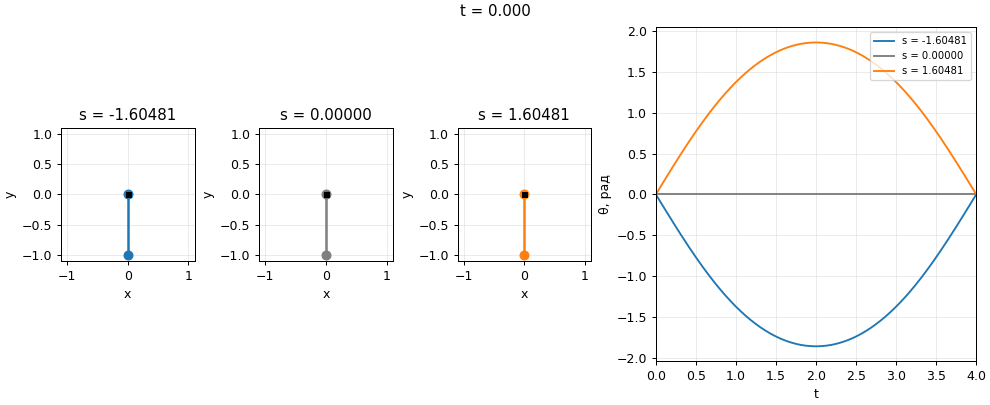

In [4]:
fine_roots, fine_t, fine_states = reference
frame_ids = np.arange(0, len(fine_t), 5)
fig = plt.figure(figsize=(11, 4.5), dpi=90, layout="constrained")
grid = fig.add_gridspec(1, 4, width_ratios=[1,1,1,2.4])
rods = []
for j in range(3):
    ax = fig.add_subplot(grid[0,j])
    rod, = ax.plot([], [], "o-", color=colors[j], linewidth=2, markersize=7)
    rods.append(rod)
    ax.plot(0,0,"ks",markersize=4)
    ax.set(xlim=(-1.1,1.1), ylim=(-1.1,1.1), aspect="equal", xlabel="x", ylabel="y",
           title=f"s = {fine_roots[j]:.5f}")
ax = fig.add_subplot(grid[0,3])
for j in range(3):
    ax.plot(fine_t, fine_states[:,j,0], color=colors[j], label=f"s = {fine_roots[j]:.5f}")
cursor = ax.axvline(0,color="black",linestyle="--")
ax.set(xlabel="t", ylabel="θ, рад", xlim=(0,4))
ax.legend(fontsize=8)
title = fig.suptitle("")


def update_frame(frame):
    i = frame_ids[frame]
    for j, rod in enumerate(rods):
        angle = fine_states[i,j,0]
        rod.set_data([0,np.sin(angle)],[0,-np.cos(angle)])
    cursor.set_xdata([fine_t[i],fine_t[i]])
    title.set_text(f"t = {fine_t[i]:.3f}")


frames = []
for frame in range(len(frame_ids)):
    update_frame(frame)
    fig.canvas.draw()
    frames.append(PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB"))
buffer = BytesIO()
frames[0].save(buffer, format="GIF", save_all=True, append_images=frames[1:], duration=50, loop=0)
plt.close(fig)
gif_data = b64encode(buffer.getvalue()).decode("ascii")
display(HTML(f'<img alt="Три решения краевой задачи" src="data:image/gif;base64,{gif_data}">'))

## Выводы

Найдены три решения: $s=0$ и $s\approx\pm1.6048130348$. Это покой и два движения с противоположными начальными скоростями.
В ненулевых решениях маятник отклоняется в одну сторону, останавливается в крайнем
положении и к $t=4$ возвращается к нулевому углу. Скорость при возвращении ненулевая.
Уточнение шага сохраняет эти решения и уменьшает различия траекторий.
Максимальная разность углов между расчётами с шагами 0.04 и 0.005 составляет
около $3.23\cdot10^{-8}$ рад в общих узлах.

Результат Ньютона зависит от начального приближения. Вблизи экстремумов невязки
производная мала, поэтому шаг Ньютона может быть большим и выйти из заданного диапазона.
На карте такие остановки выделены отдельно от успешной сходимости.

Одинаковые положения в начале и конце не задают начальную скорость и энергию.
У маятника могут быть разные движения между этими моментами. Единственность задачи
Коши относится к заданным начальному углу и скорости, а здесь вместо скорости
задаётся угол в другой момент времени.